# Implement Simplex Algorithm

**Team Members**

1. **SAI KRISHNA SHANIGARAPU** – EE23BTECH11054  
2. **YAKKALA AMARNATH KARTHIK** – EE23BTECH11066  
3. **P DEEPAK REDDY** – EE23BTECH11047

We implement the Simplex Algorithm using the method discussed in the class. The test problem is **Custom made** - we created our own dataset and used the opensource solvers to get the optimal value for reference.

In [25]:
import numpy as np
import urllib.request
import math
import time

url = "https://raw.githubusercontent.com/ee23btech11054/Linearopt_simplex/main/input.csv"

urllib.request.urlretrieve(url, "input.csv")

data = np.genfromtxt("input.csv", delimiter=",", filling_values=0.0)

c = data[0, :-1]
A = data[1:, :-1]
b = data[1:, -1]

m, n = A.shape

print("MATRIX VALIDATION")
print("A shape:", A.shape)
print("Number of constraints:", m)
print("Number of variables:", n)

rank_A = np.linalg.matrix_rank(A)

print("Rank of A:", rank_A)
print("Required rank:", n)

if rank_A == n:
    print("Assumption rank(A) = n: Satisfied")
else:
    raise ValueError("The matrix A does not have full column rank.")

if np.all(A @ np.zeros(n) <= b):
    print("Initial point x = 0 is feasible.")
else:
    print("Origin is not feasible. Enumeration is required.")

MATRIX VALIDATION
A shape: (80, 75)
Number of constraints: 80
Number of variables: 75
Rank of A: 75
Required rank: 75
Assumption rank(A) = n: Satisfied
Initial point x = 0 is feasible.


## Simplex method used

We work with the constraints in the form

$$
Ax \leq b, \qquad x \geq 0.
$$

At a vertex, we choose $n$ linearly independent active constraints. Let their matrix and right-hand side be $A_0$ and $b_0$. The current vertex $x^{(0)}$ satisfies

$$
A_0x^{(0)}=b_0.
$$

The directions towards its neighbouring vertices are the columns of

$$
V=-A_0^{-1}.
$$

For a direction $v_i$, we check whether the objective increases:

$$
c^Tv_i>0.
$$

If it does, we move along that direction:

$$
x=x^{(0)}+tv_i, \qquad t\geq 0.
$$

The largest feasible step is found using the minimum-ratio test:

$$
t_{\min}=\min_{s:\,A_sv_i>0}\frac{b_s-A_sx^{(0)}}{A_sv_i},
$$

where the current active constraints are left out of the minimum. The constraint that gives the minimum becomes active at the next vertex. We repeat this process until no neighbouring direction increases the objective. If an improving direction has no constraint limiting its step, the objective is unbounded.

The code solves linear systems to obtain the same directions as $-A_0^{-1}$, without explicitly forming a matrix inverse.

**Initial vertex:** We first test $x=0$. If it is infeasible, we enumerate sets of $n$ independent active constraints and test their intersection. The enumeration is limited by a setting in the next cell so that a very large search does not run indefinitely.

The reference value of optimum solution is around 2092.15. Let's check this using our own simplex algorithm.

In [26]:
# ----------------------------------------------------------------------
# Problem:  maximize c^T x   subject to  A x <= b,  x >= 0
# x >= 0 is written as  -x <= 0, so every constraint has the form  C x <= d.
# ----------------------------------------------------------------------
PRINT_FULL_VERTICES = True      # False -> print only objective values (and full first/last vertex)
MAX_ITERATIONS      = 100000
TOL                 = 1e-9

def build_constraints(A, b):
    n = A.shape[1]
    return np.vstack((-np.eye(n), A)), np.concatenate((np.zeros(n), b))

def is_feasible(C, d, x, tol=1e-7):
    return bool(np.all(C @ x - d <= tol * (1.0 + np.abs(d))))

# ----------------------------------------------------------------------
#   x      : current extreme point, basis : indices of the n tight rows (A')
#   Directions to neighbours = columns of  -(A')^{-1}
#   Move along a direction v with c^T v > 0 by the largest feasible step
#       t = min_s (d_s - C_s x) / (C_s v)   over rows s not in A' with C_s v > 0
#   No such row  -> unbounded.  No improving direction -> optimal.
# ----------------------------------------------------------------------
def simplex(cost, C, d, x, basis):
    N = len(x)
    basis = list(basis)
    history = [(x.copy(), float(cost @ x))]
    for _ in range(MAX_ITERATIONS):
        directions = np.linalg.solve(C[basis], -np.eye(N))      # = -(A')^{-1}
        slack = d - C @ x
        not_basis = np.ones(C.shape[0], dtype=bool)
        not_basis[basis] = False

        moved = False
        for i in range(N):
            v = directions[:, i]
            if cost @ v <= TOL:                                  # not an improving neighbour
                continue
            rate = C @ v
            cand = np.where(not_basis & (rate > TOL))[0]
            if len(cand) == 0:                                   # can go on forever
                return "unbounded", x, history
            ratios = slack[cand] / rate[cand]
            k = np.argmin(ratios)
            basis[i] = int(cand[k])                              # constraint i leaves, cand[k] enters
            x = np.linalg.solve(C[basis], d[basis])              # the neighbouring vertex
            history.append((x.copy(), float(cost @ x)))
            moved = True
            break                                                # move to the first improving neighbour
        if not moved:
            return "optimal", x, history
    return "iteration_limit", x, history

# ----------------------------------------------------------------------
# Initial feasible vertex.
#   b >= 0 : the origin is a vertex (the n constraints -x <= 0 are tight).
#   otherwise : Phase 1.  Solve   max -t  s.t.  Ax - t <= b, x >= 0, t >= 0
#               with the same simplex, starting from the vertex (0, t0).
#               Original problem is feasible  <=>  optimum has t = 0.
# ----------------------------------------------------------------------
def find_initial_vertex(A, b, C, d):
    m, n = A.shape
    if is_feasible(C, d, np.zeros(n)):
        return "found", np.zeros(n), list(range(n)), 0

    C1 = np.zeros((n + m + 1, n + 1))
    C1[:n, :n] = -np.eye(n)
    C1[n:n + m, :n] = A
    C1[n:n + m, n] = -1.0
    C1[n + m, n] = -1.0
    d1 = np.concatenate((np.zeros(n), b, [0.0]))
    cost1 = np.zeros(n + 1); cost1[n] = -1.0

    worst = int(np.argmin(b))                                    # most violated row at x = 0
    x1 = np.zeros(n + 1); x1[n] = -b[worst]                      # t0 = -min(b) > 0
    basis1 = list(range(n)) + [n + worst]                        # n+1 independent tight rows

    status, x1, hist = simplex(cost1, C1, d1, x1, basis1)
    if status != "optimal" or x1[n] > 1e-7:
        return "infeasible", None, None, len(hist) - 1

    x = np.maximum(x1[:n], 0.0)
    tight = np.where(np.abs(C @ x - d) <= 1e-7 * (1.0 + np.abs(d)))[0]
    chosen = []                                                  # pick n independent tight rows
    for r in tight:
        if np.linalg.matrix_rank(C[chosen + [r]]) > len(chosen):
            chosen.append(int(r))
        if len(chosen) == n:
            break
    if len(chosen) < n:
        return "infeasible", None, None, len(hist) - 1
    x = np.linalg.solve(C[chosen], d[chosen])
    return "found", x, chosen, len(hist) - 1

def show(x):
    return np.array2string(x, precision=6, suppress_small=True, threshold=np.inf, max_line_width=120)

# ----------------------------------------------------------------------
# Run
# ----------------------------------------------------------------------
C, d = build_constraints(A, b)
t0 = time.time()

print("=" * 60)
print("1. INITIAL FEASIBLE SOLUTION")
print("=" * 60)
status, x0, basis0, phase1_moves = find_initial_vertex(A, b, C, d)

if status == "infeasible":
    print("There is no feasible solution.")
else:
    print("Initial feasible vertex:")
    print(show(x0))
    print("Objective value at it:", float(c @ x0))
    if phase1_moves:
        print(f"(found by Phase 1 in {phase1_moves} simplex moves)")

    result, x_opt, history = simplex(c, C, d, x0, basis0)

    print("\n" + "=" * 60)
    print("2. SEQUENCE OF VERTICES VISITED")
    print("=" * 60)
    for k, (vertex, value) in enumerate(history):
        print(f"Vertex {k}: objective value = {value:.6f}")
        if PRINT_FULL_VERTICES or k in (0, len(history) - 1):
            print("   x =", show(vertex))
    print("Total vertices visited:", len(history))

    print("\n" + "=" * 60)
    print("3. RESULT")
    print("=" * 60)
    if result == "optimal":
        print("Optimum vertex:")
        print(show(x_opt))
        print("Optimum value:", float(c @ x_opt))
    elif result == "unbounded":
        print("The objective function is not bounded.")
    else:
        print("Stopped after the iteration limit without reaching an optimum.")

print(f"\nTotal time: {time.time() - t0:.2f} s")

Streaming output truncated to the last 5000 lines.
Vertex 444: objective value = 2452.079928
   x = [ 0.        0.501994  4.575118  0.       11.797124  2.940496  0.        3.254651  0.        0.        9.253018
  0.591678  0.        0.       -0.        5.215819  7.067026  7.314767 15.248686 10.271441  0.163681 10.899765
  0.       -0.        0.        1.965872  0.       -0.       15.473435  5.284014 19.773166  4.961233  5.274567
  0.       -0.       -0.       -0.       -0.       -0.       -0.        4.436846 -0.       -0.       10.414596
 -0.        2.269145 -0.        0.       -0.       -0.        8.333018  6.549147  3.064403  4.611889 -0.
 -0.       -0.       -0.       -0.       -0.       -0.       -0.       -0.       -0.       -0.       -0.
 -0.       -0.       -0.       -0.       -0.       -0.       -0.       -0.       -0.      ]
Vertex 445: objective value = 2452.185699
   x = [-0.        0.450293  4.481675  0.       11.824248  2.943189  0.        3.304422 -0.       -0.        9.3

CERTIFICATE OF OPTIMALITY
  Feasible (Cx <= d)            : True
  All multipliers lambda >= 0   : True (min = 1.630e-02)
  Primal  c^T x                 : 2902.1501056858865
  Dual    lambda^T d'           : 2902.1501056858865
  Strictly increasing path      : True


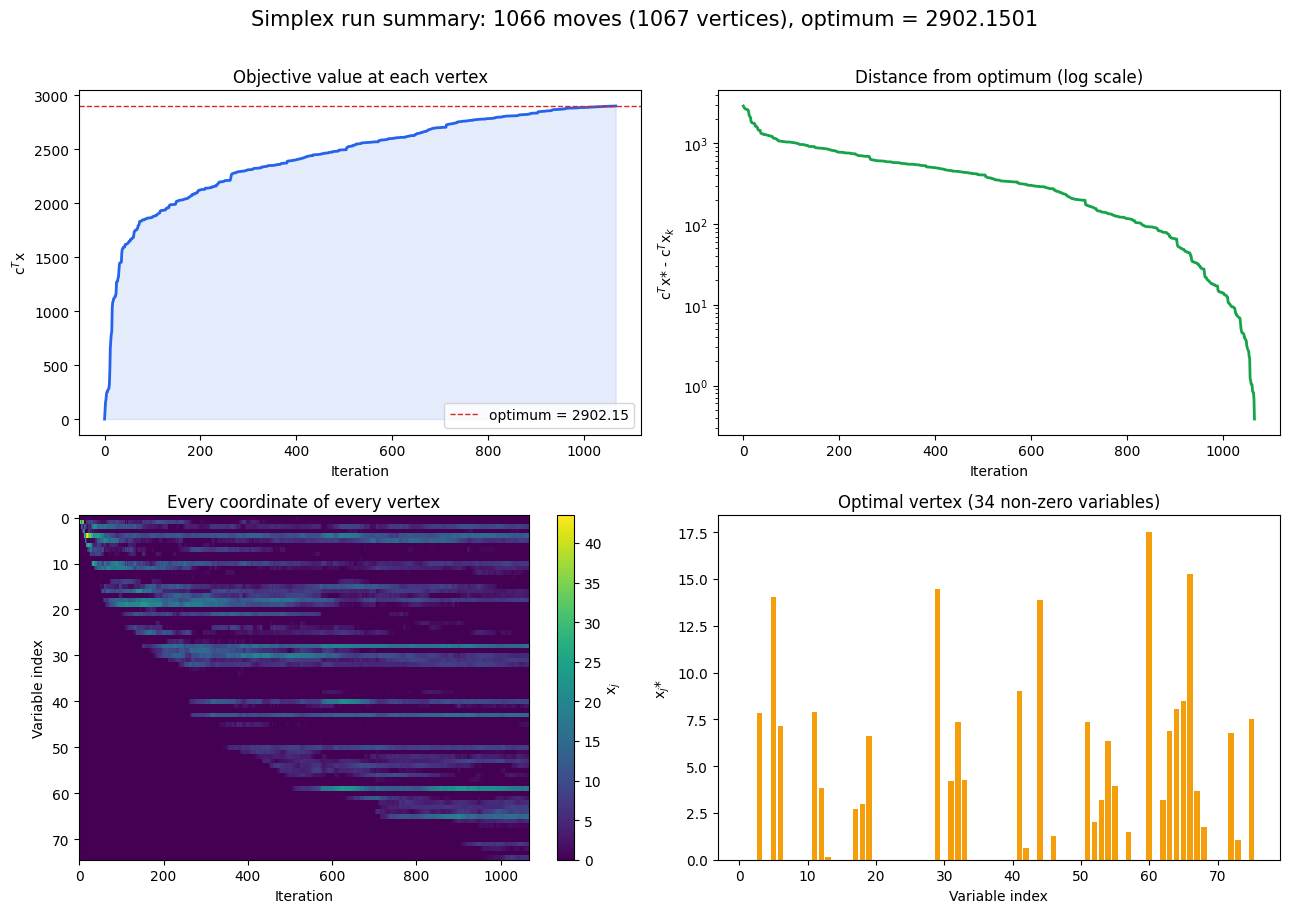

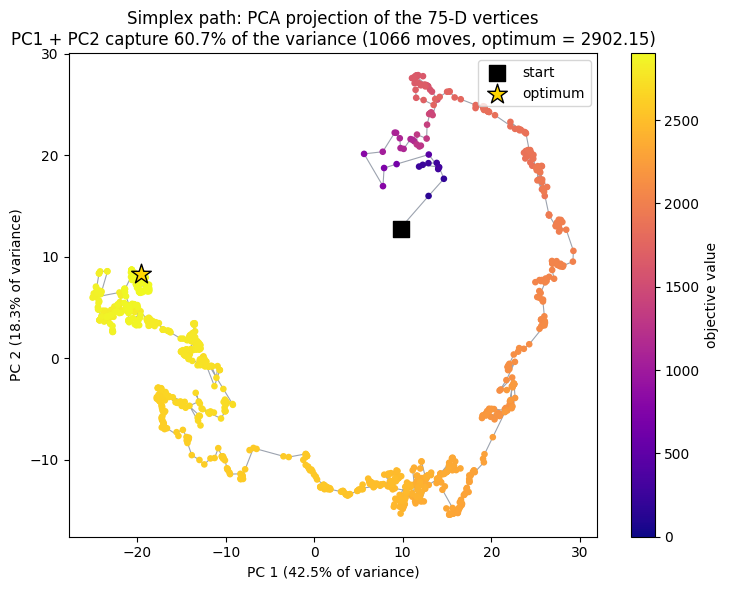

In [29]:
import numpy as np
import matplotlib.pyplot as plt

values = np.array([v for _, v in history])
verts  = np.array([x for x, _ in history])            # (iterations+1, n)
iters  = np.arange(len(values))

# ---------- 1. Optimality certificate (ties to the proof in Lecture 12) ----------
tight = np.where(np.abs(C @ x_opt - d) <= 1e-7 * (1 + np.abs(d)))[0]
rows = []
for r in tight:
    if np.linalg.matrix_rank(C[rows + [r]]) > len(rows):
        rows.append(int(r))
lam = np.linalg.solve(C[rows].T, c)                    # c = sum_i lam_i * (row i of A')
print("CERTIFICATE OF OPTIMALITY")
print("  Feasible (Cx <= d)            :", bool(np.all(C @ x_opt - d <= 1e-7 * (1 + np.abs(d)))))
print("  All multipliers lambda >= 0   :", bool(np.all(lam >= -1e-7)), f"(min = {lam.min():.3e})")
print("  Primal  c^T x                 :", float(c @ x_opt))
print("  Dual    lambda^T d'           :", float(lam @ d[rows]))
print("  Strictly increasing path      :", bool(np.all(np.diff(values) > 0)))

# ---------- 2. Dashboard ----------
fig, ax = plt.subplots(2, 2, figsize=(13, 9))

ax[0, 0].plot(iters, values, color="#2563eb", lw=2)
ax[0, 0].fill_between(iters, values, alpha=0.12, color="#2563eb")
ax[0, 0].axhline(values[-1], ls="--", color="#dc2626", lw=1, label=f"optimum = {values[-1]:.2f}")
ax[0, 0].set(title="Objective value at each vertex", xlabel="Iteration", ylabel="c$^T$x")
ax[0, 0].legend(loc="lower right")

gap = values[-1] - values[:-1]
ax[0, 1].semilogy(iters[:-1], gap, color="#16a34a", lw=2)
ax[0, 1].set(title="Distance from optimum (log scale)", xlabel="Iteration", ylabel="c$^T$x* - c$^T$x$_k$")

im = ax[1, 0].imshow(verts.T, aspect="auto", cmap="viridis", interpolation="nearest")
ax[1, 0].set(title="Every coordinate of every vertex", xlabel="Iteration", ylabel="Variable index")
fig.colorbar(im, ax=ax[1, 0], label="x$_j$")

ax[1, 1].bar(np.arange(1, len(x_opt) + 1), x_opt, color=np.where(x_opt > 1e-9, "#f59e0b", "#d1d5db"))
ax[1, 1].set(title=f"Optimal vertex ({int((x_opt > 1e-9).sum())} non-zero variables)",
             xlabel="Variable index", ylabel="x$_j$*")

plt.suptitle(f"Simplex run summary: {len(history) - 1} moves ({len(history)} vertices), "
             f"optimum = {values[-1]:.4f}", fontsize=15, y=1.01)
plt.tight_layout(); plt.savefig("simplex_summary.png", dpi=150, bbox_inches="tight"); plt.show()

# ---------- 3. The 75-D path squeezed onto 2-D (PCA) ----------
centered = verts - verts.mean(axis=0)
_, S, Vt = np.linalg.svd(centered, full_matrices=False)
var_ratio = S**2 / np.sum(S**2)
p = centered @ Vt[:2].T

fig, a = plt.subplots(figsize=(7.5, 6))
a.plot(p[:, 0], p[:, 1], color="#9ca3af", lw=0.8, zorder=1)
sc = a.scatter(p[:, 0], p[:, 1], c=values, cmap="plasma", s=14, zorder=2)
a.scatter(*p[0], s=140, marker="s", color="black", label="start", zorder=3)
a.scatter(*p[-1], s=220, marker="*", color="gold", edgecolor="black", label="optimum", zorder=3)
fig.colorbar(sc, label="objective value"); a.legend()
a.set(title=f"Simplex path: PCA projection of the {verts.shape[1]}-D vertices\n"
            f"PC1 + PC2 capture {100 * var_ratio[:2].sum():.1f}% of the variance "
            f"({len(history) - 1} moves, optimum = {values[-1]:.2f})",
      xlabel=f"PC 1 ({100 * var_ratio[0]:.1f}% of variance)",
      ylabel=f"PC 2 ({100 * var_ratio[1]:.1f}% of variance)")
plt.tight_layout(); plt.savefig("simplex_path_pca.png", dpi=150); plt.show()